# DE-LU day-ahead model evaluation

Walk-forward test-set forecasts (2024-11-01 to 2026-10-31) for the models in
`results/forecasts_test_all.parquet`, as written by `scripts/report.py --save`.

- Prices are in EUR/MWh and scored at the native 15-minute periods (hourly values before
  October 2025 are forward-filled to quarter-hours).
- **Caveat:** the features use TSO day-ahead wind and solar forecasts, which are published
  after the 12:00 CET gate closure. Live errors will be somewhat higher than these.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from energy_price_predictor.backtest import breakdown, daily_mae, dm_matrix, metrics_table
from energy_price_predictor.features import LOCAL_TZ

RESULTS_DIR = Path.cwd().parent / "results" if Path.cwd().name == "notebooks" else Path("results")
results = pd.read_parquet(RESULTS_DIR / "forecasts_test_all.parquet").dropna()
models = [column for column in results.columns if column != "actual"]

# Fixed colour per model (categorical slots in order); the actual price is neutral ink.
ACTUAL_COLOUR = "#0b0b0b"
MODEL_COLOURS = {
    "gbm_tuned": "#2a78d6",
    "lear": "#eb6834",
    "ensemble": "#1baf7a",
    "naive": "#eda100",
    "seasonal_naive": "#e87ba4",
}
MAIN_MODELS = [m for m in ["gbm_tuned", "lear", "ensemble"] if m in models]
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"]
)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "timezone": LOCAL_TZ,  # date ticks in local delivery time
})

local = results.tz_convert(LOCAL_TZ)
print(f"{len(results):,d} periods, {local.index.normalize().nunique()} days, models: {models}")

70,080 periods, 730 days, models: ['seasonal_naive', 'lear', 'naive', 'gbm_tuned', 'ensemble']


## Headline metrics

In [2]:
metrics_table(results).round(3)

,mae,rmse,mae_hourly,rmae
model,,,,
seasonal_naive,38.841,62.416,38.568,1.190
lear,17.224,31.641,16.523,0.528
naive,32.631,52.612,32.387,1.000
gbm_tuned,13.785,26.458,13.248,0.422
ensemble,14.154,26.857,13.587,0.434


In [3]:
print("Diebold-Mariano one-sided p-values (column model beats row model):")
dm_matrix(results).round(4)

Diebold-Mariano one-sided p-values (column model beats row model):


,seasonal_naive,lear,naive,gbm_tuned,ensemble
seasonal_naive,NaN,0.0,0.0,0.0000,0.0000
lear,1.0,NaN,1.0,0.0000,0.0000
naive,1.0,0.0,NaN,0.0000,0.0000
gbm_tuned,1.0,1.0,1.0,NaN,0.9906
ensemble,1.0,1.0,1.0,0.0094,NaN


## Predicted vs actual over time

Daily mean prices across the whole test period. Daily averaging hides the intraday shape
but shows whether the models track the level.

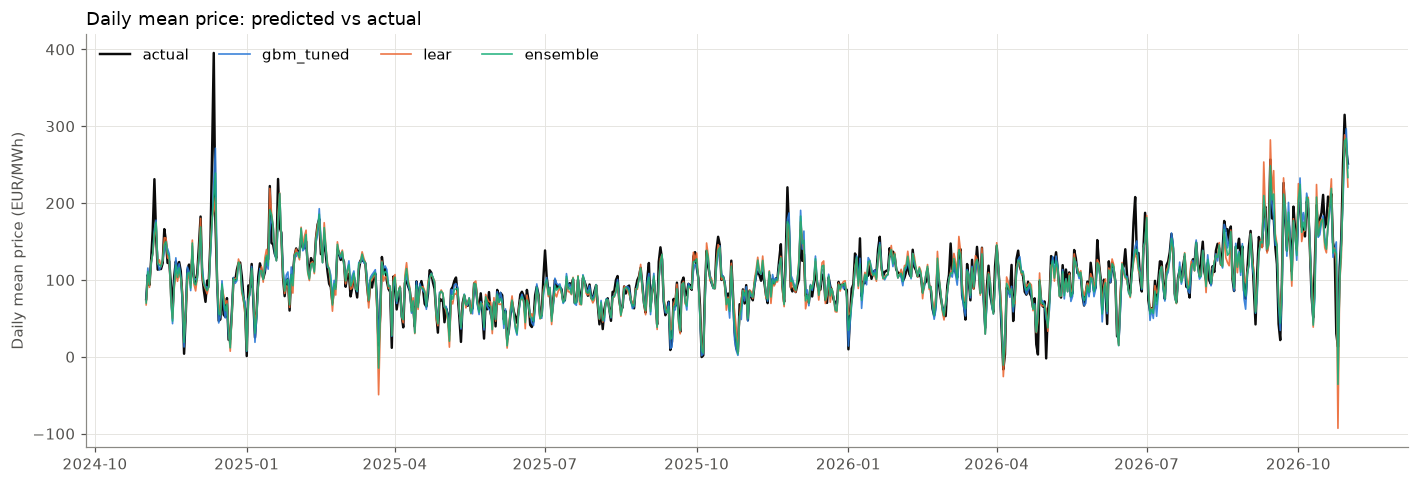

In [4]:
daily = local.groupby(local.index.normalize()).mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(daily.index, daily["actual"], color=ACTUAL_COLOUR, linewidth=1.6, label="actual")
for model in MAIN_MODELS:
    ax.plot(daily.index, daily[model], color=MODEL_COLOURS[model], linewidth=1.1, alpha=0.9, label=model)
ax.set_ylabel("Daily mean price (EUR/MWh)")
ax.set_title("Daily mean price: predicted vs actual", loc="left")
ax.legend(ncol=len(MAIN_MODELS) + 1, loc="upper left")
fig.tight_layout()

### Example weeks at full resolution

Three weeks picked from the data: the week where `gbm_tuned` did best, the week where it
did worst, and the most recent full week.

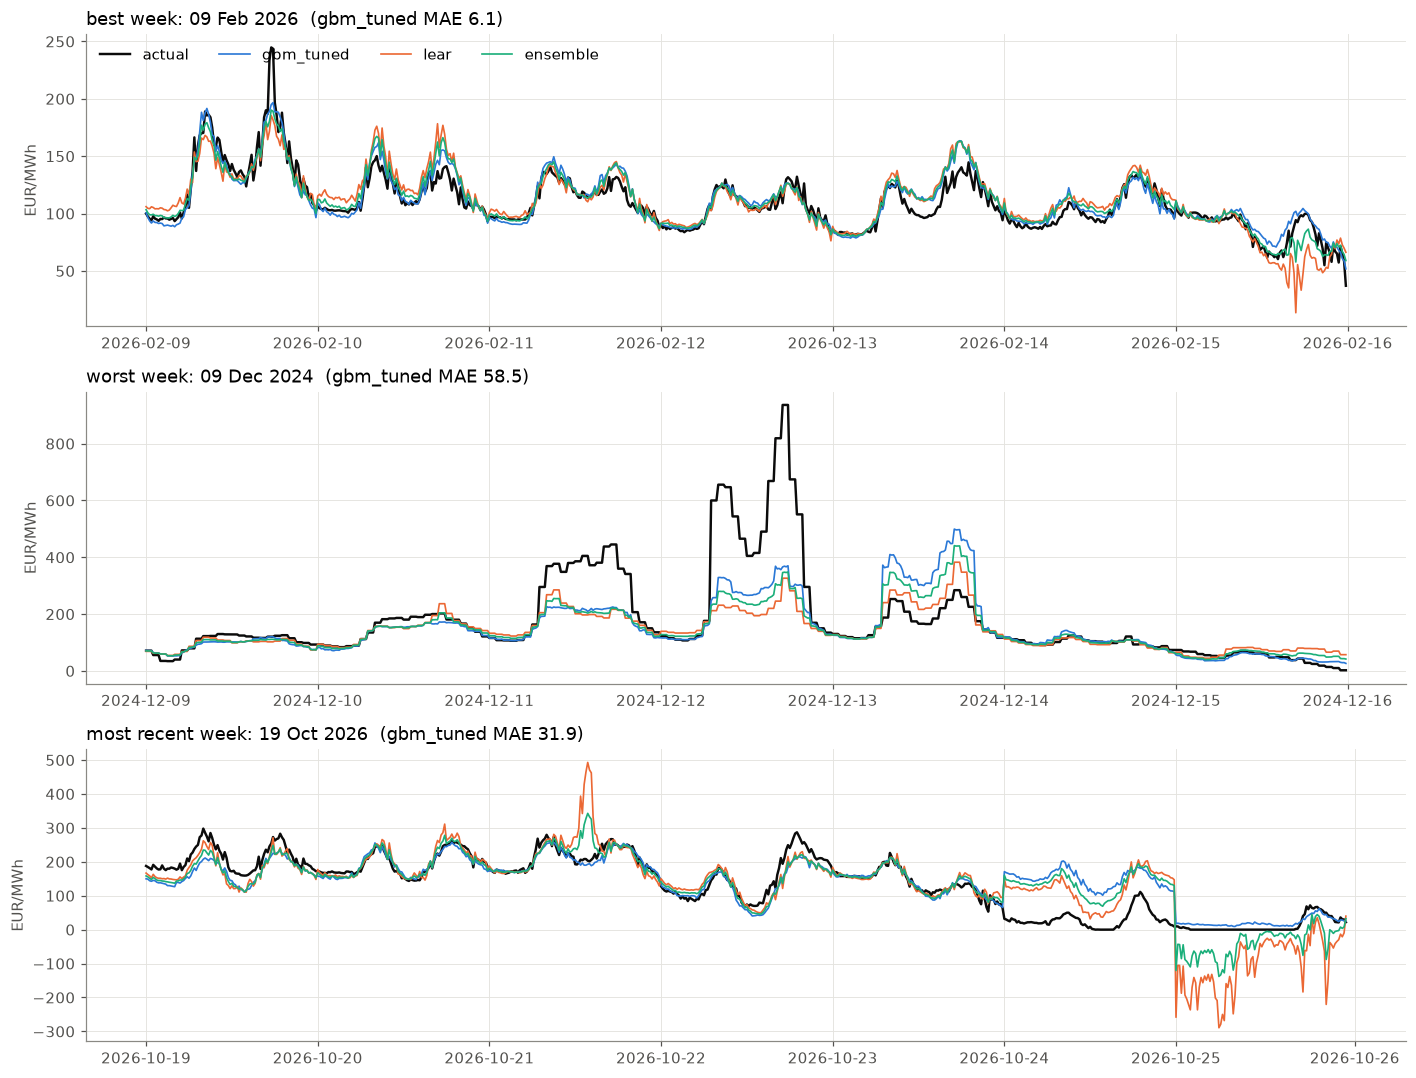

In [5]:
def week_window(start: pd.Timestamp) -> pd.DataFrame:
    return local[(local.index >= start) & (local.index < start + pd.Timedelta(days=7))]


weekly_mae = (local["gbm_tuned"] - local["actual"]).abs().resample("W-MON", label="left", closed="left").mean()
full_weeks = weekly_mae[local.resample("W-MON", label="left", closed="left").size() >= 7 * 92]
example_weeks = {
    "best week": full_weeks.idxmin(),
    "worst week": full_weeks.idxmax(),
    "most recent week": full_weeks.index.max(),
}

fig, axes = plt.subplots(len(example_weeks), 1, figsize=(13, 3.3 * len(example_weeks)))
for ax, (label, start) in zip(axes, example_weeks.items()):
    window = week_window(start)
    ax.plot(window.index, window["actual"], color=ACTUAL_COLOUR, linewidth=1.6, label="actual")
    for model in MAIN_MODELS:
        ax.plot(window.index, window[model], color=MODEL_COLOURS[model], linewidth=1.1, label=model)
    ax.set_title(f"{label}: {start:%d %b %Y}  (gbm_tuned MAE {weekly_mae[start]:.1f})", loc="left")
    ax.set_ylabel("EUR/MWh")
axes[0].legend(ncol=len(MAIN_MODELS) + 1, loc="upper left")
fig.tight_layout()

## Predicted vs actual scatter

Each panel is a 2-D histogram of 15-minute periods (darker = more periods). Points on the
dashed diagonal are perfect forecasts. The axis range is clipped to the 0.5-99.5 %
range of actual prices so the bulk of the distribution is visible.

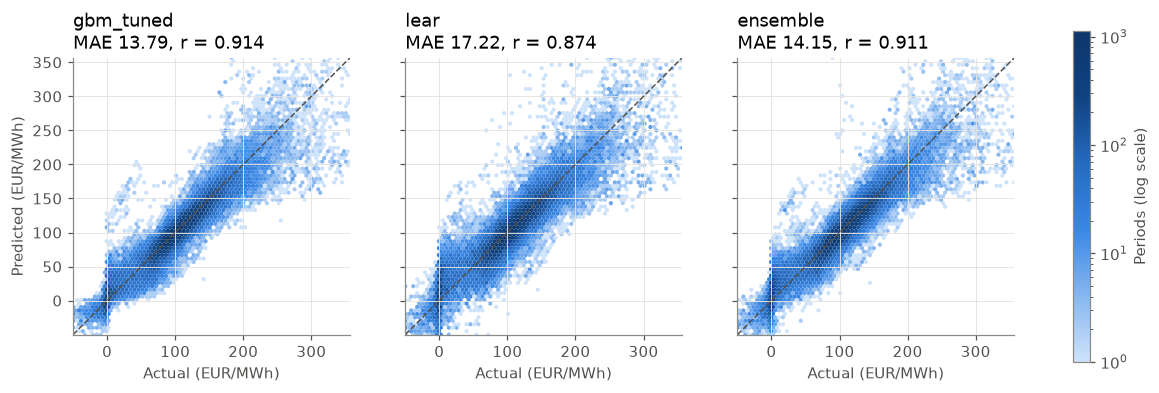

In [6]:
low, high = results["actual"].quantile([0.005, 0.995])
lims = (low - 10, high + 10)

fig, axes = plt.subplots(1, len(MAIN_MODELS), figsize=(4.6 * len(MAIN_MODELS), 4.6), sharex=True, sharey=True)
for ax, model in zip(np.atleast_1d(axes), MAIN_MODELS):
    hb = ax.hexbin(results["actual"], results[model], gridsize=70, extent=(*lims, *lims),
                   cmap=BLUE_RAMP, bins="log", mincnt=1, linewidths=0)
    ax.plot(lims, lims, color="#52514e", linestyle="--", linewidth=1)
    mae = (results[model] - results["actual"]).abs().mean()
    correlation = results[[model, "actual"]].corr().iloc[0, 1]
    ax.set_title(f"{model}\nMAE {mae:.2f}, r = {correlation:.3f}", loc="left")
    ax.set_xlabel("Actual (EUR/MWh)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
np.atleast_1d(axes)[0].set_ylabel("Predicted (EUR/MWh)")
fig.colorbar(hb, ax=axes, label="Periods (log scale)", shrink=0.85)

### Calibration by price level

Mean prediction and MAE within deciles of the actual price. A well-calibrated model sits
on the diagonal; tree models typically under-predict the extremes.

,seasonal_naive,lear,naive,gbm_tuned,ensemble
actual,,,,,
"(-499.991, 6.55]",50.22,26.08,42.07,14.72,18.97
"(6.55, 63.99]",53.44,22.02,45.71,16.43,17.21
"(63.99, 82.47]",37.34,13.91,28.89,11.64,11.23
"(82.47, 91.69]",26.14,10.52,21.45,8.36,8.51
"(91.69, 100.95]",25.50,10.26,21.94,8.06,8.24
"(100.95, 110.51]",26.94,10.45,21.71,8.40,8.55
"(110.51, 123.07]",28.56,11.51,24.57,9.38,9.47
"(123.07, 139.9]",31.98,13.11,26.82,10.86,10.97
"(139.9, 167.361]",34.66,15.55,29.65,12.89,12.98


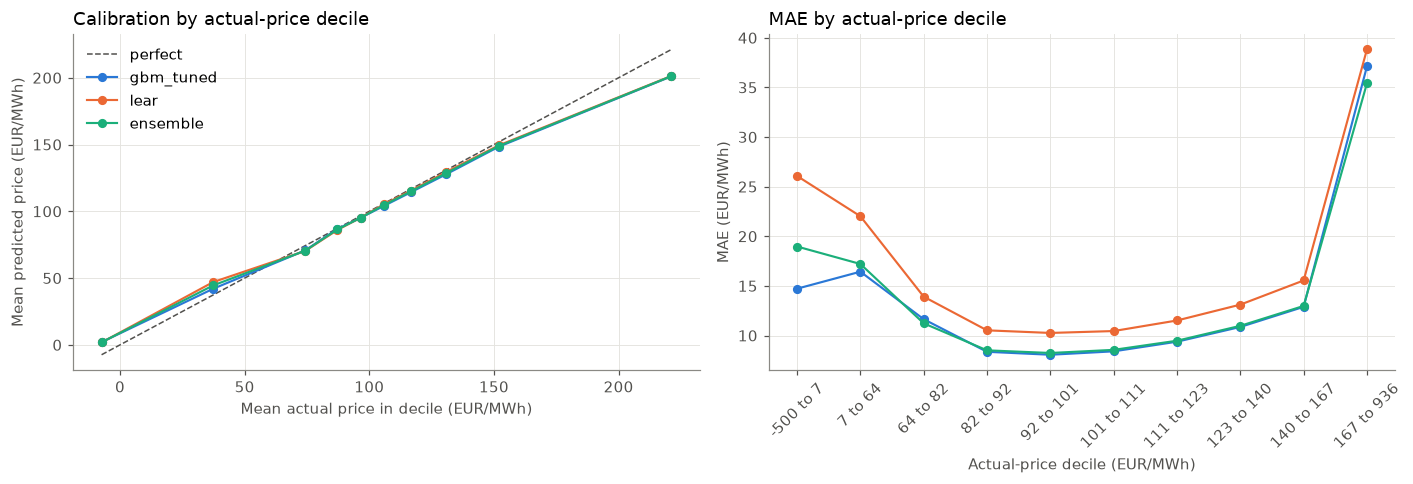

In [7]:
bins = pd.qcut(results["actual"], 10)
by_level = results.groupby(bins, observed=True)
mean_by_level = by_level.mean()
mae_by_level = pd.DataFrame({m: by_level.apply(lambda g, m=m: (g[m] - g["actual"]).abs().mean()) for m in models})

fig, (ax_cal, ax_mae) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_cal.plot(mean_by_level["actual"], mean_by_level["actual"], color="#52514e", linestyle="--",
            linewidth=1, label="perfect")
for model in MAIN_MODELS:
    ax_cal.plot(mean_by_level["actual"], mean_by_level[model], marker="o", markersize=5,
                color=MODEL_COLOURS[model], label=model)
ax_cal.set_xlabel("Mean actual price in decile (EUR/MWh)")
ax_cal.set_ylabel("Mean predicted price (EUR/MWh)")
ax_cal.set_title("Calibration by actual-price decile", loc="left")
ax_cal.legend()

labels = [f"{interval.left:.0f} to {interval.right:.0f}" for interval in mae_by_level.index]
for model in MAIN_MODELS:
    ax_mae.plot(labels, mae_by_level[model], marker="o", markersize=5, color=MODEL_COLOURS[model], label=model)
ax_mae.set_xlabel("Actual-price decile (EUR/MWh)")
ax_mae.set_ylabel("MAE (EUR/MWh)")
ax_mae.set_title("MAE by actual-price decile", loc="left")
ax_mae.tick_params(axis="x", rotation=45)
fig.tight_layout()
mae_by_level.round(2)

## Error by time of day and over time

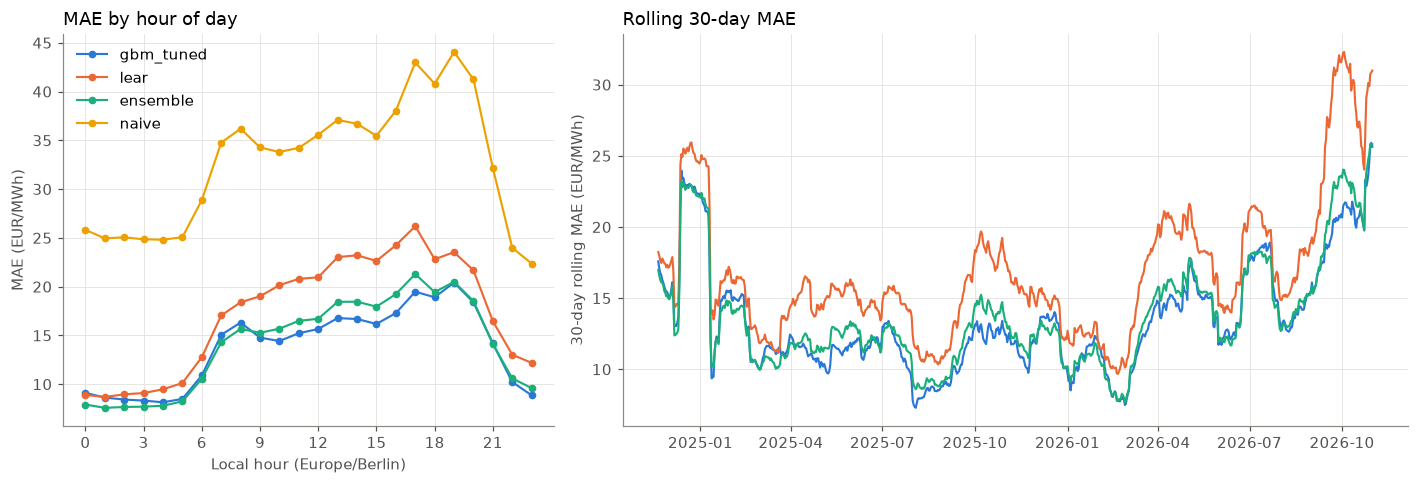

In [8]:
by_hour = breakdown(results, "hour")

fig, (ax_hour, ax_roll) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
for model in MAIN_MODELS + [m for m in ["naive"] if m in models]:
    ax_hour.plot(by_hour.index, by_hour[model], marker="o", markersize=4, color=MODEL_COLOURS[model], label=model)
ax_hour.set_xlabel("Local hour (Europe/Berlin)")
ax_hour.set_ylabel("MAE (EUR/MWh)")
ax_hour.set_xticks(range(0, 24, 3))
ax_hour.set_title("MAE by hour of day", loc="left")
ax_hour.legend()

daily_errors = daily_mae(results)
rolling = daily_errors.rolling(30, min_periods=20).mean()
for model in MAIN_MODELS:
    ax_roll.plot(rolling.index, rolling[model], color=MODEL_COLOURS[model], label=model)
ax_roll.set_ylabel("30-day rolling MAE (EUR/MWh)")
ax_roll.set_title("Rolling 30-day MAE", loc="left")
fig.tight_layout()

In [9]:
print("MAE by month:")
breakdown(results, "month")[MAIN_MODELS + ["naive"]].round(2)

MAE by month:


,gbm_tuned,lear,ensemble,naive
month,,,,
1,13.61,14.91,13.02,35.11
2,8.96,11.30,9.04,24.27
3,13.53,16.78,13.63,33.92
4,12.49,16.99,13.43,30.24
5,12.67,16.32,13.57,24.95
6,14.84,17.34,14.73,32.54
7,11.45,14.64,11.94,19.88
8,12.11,14.72,12.13,21.07
9,16.89,24.69,18.89,47.96


## Residuals

Residual = predicted - actual. A positive mean means the model over-predicts on average.

,count,mean,std,min,5%,25%,50%,75%,95%,max
gbm_tuned,70080.0,-2.22,26.36,-570.29,-31.43,-9.89,-1.23,6.88,25.75,443.09
lear,70080.0,-1.32,31.61,-609.93,-37.38,-11.28,-0.94,9.56,37.00,534.95
ensemble,70080.0,-1.77,26.80,-590.11,-30.84,-9.88,-1.10,7.62,28.10,448.06


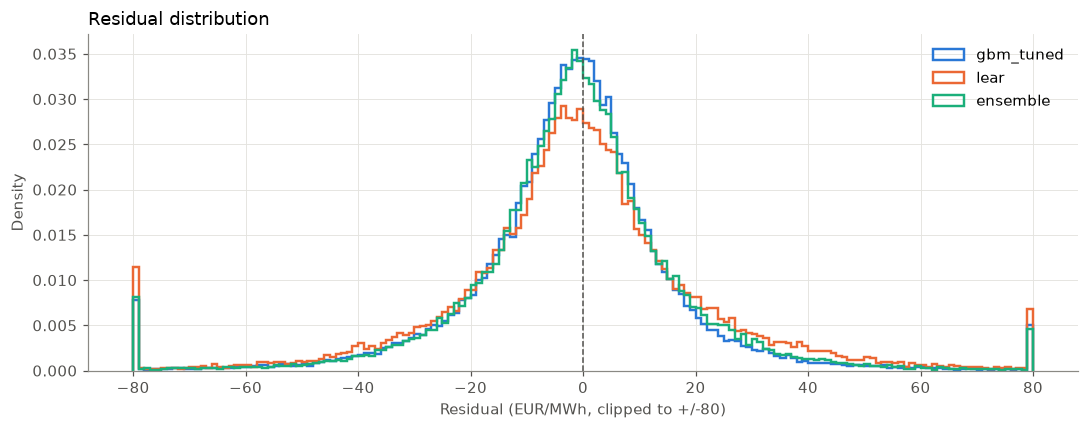

In [10]:
residuals = pd.DataFrame({m: results[m] - results["actual"] for m in MAIN_MODELS})

fig, ax = plt.subplots(figsize=(10, 4))
edges = np.linspace(-80, 80, 161)
for model in MAIN_MODELS:
    ax.hist(residuals[model].clip(-80, 80), bins=edges, histtype="step", linewidth=1.6,
            color=MODEL_COLOURS[model], label=model, density=True)
ax.axvline(0, color="#52514e", linewidth=1, linestyle="--")
ax.set_xlabel("Residual (EUR/MWh, clipped to +/-80)")
ax.set_ylabel("Density")
ax.set_title("Residual distribution", loc="left")
ax.legend()
fig.tight_layout()

residuals.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2)

## Worst days

The ten days with the largest `gbm_tuned` daily MAE, and the actual vs predicted profile
for the worst four.

,gbm_tuned,lear,ensemble,naive
valid_time,,,,
2024-12-12,170.4,216.0,192.6,129.2
2026-10-24,119.3,89.9,104.6,138.1
2024-12-13,95.0,32.5,62.9,220.0
2024-12-11,93.2,93.6,93.2,116.6
2024-11-06,77.9,90.4,83.9,66.3
2026-05-01,65.4,74.1,69.2,77.9
2026-06-24,64.1,78.1,69.3,33.1
2026-04-26,63.7,59.2,60.8,88.2
2025-01-15,62.4,28.7,39.4,95.4


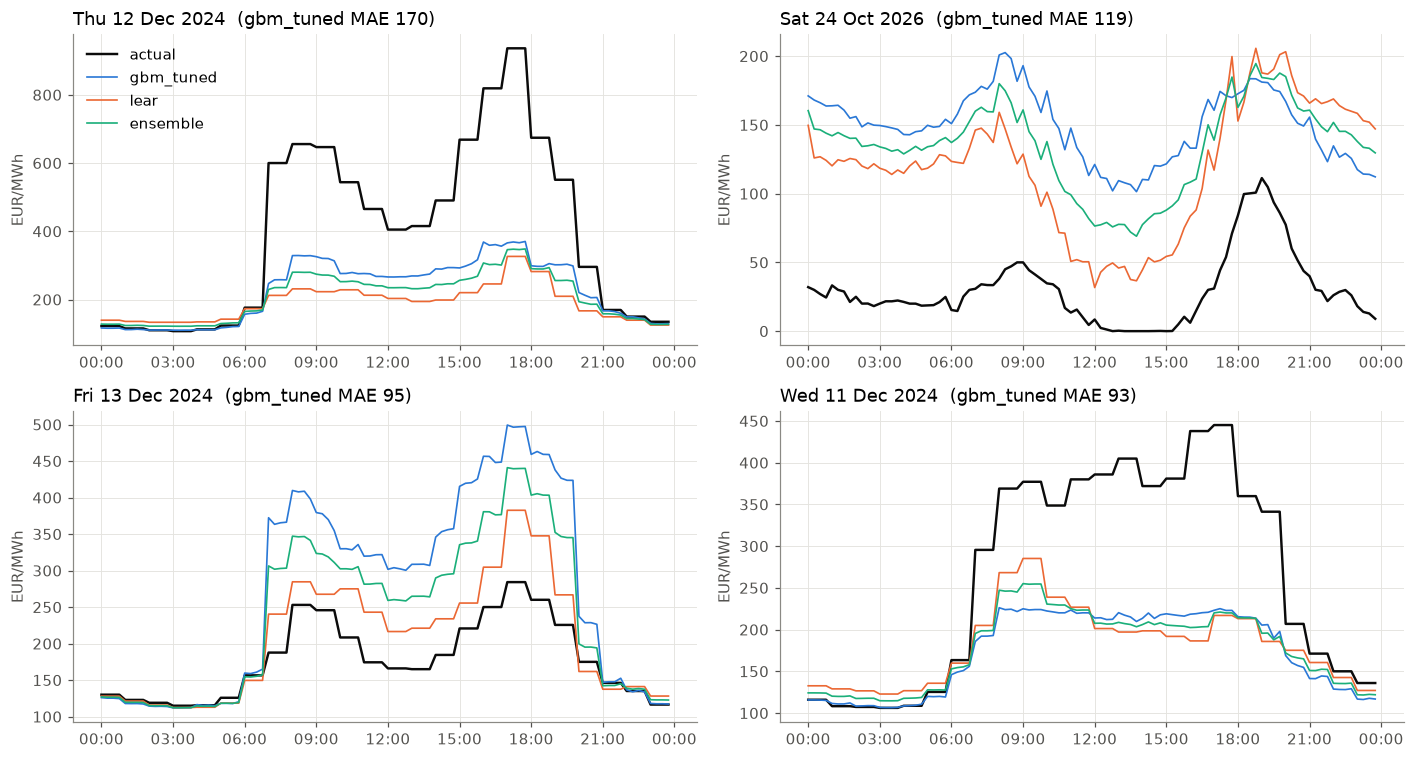

In [11]:
worst = daily_errors.sort_values("gbm_tuned", ascending=False).head(10)
display(worst[MAIN_MODELS + ["naive"]].round(1))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=False)
for ax, day in zip(axes.flat, worst.index[:4]):
    rows = local[local.index.normalize() == pd.Timestamp(day).tz_localize(LOCAL_TZ)]
    ax.plot(rows.index, rows["actual"], color=ACTUAL_COLOUR, linewidth=1.6, label="actual")
    for model in MAIN_MODELS:
        ax.plot(rows.index, rows[model], color=MODEL_COLOURS[model], linewidth=1.1, label=model)
    ax.set_title(f"{pd.Timestamp(day):%a %d %b %Y}  (gbm_tuned MAE {worst.loc[day, 'gbm_tuned']:.0f})", loc="left")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=LOCAL_TZ))
    ax.set_ylabel("EUR/MWh")
axes.flat[0].legend(loc="best")
fig.tight_layout()